# ✈️ Uçuş Rötar Tahmini — Uçtan Uca Yapay Zeka Projesi: Veriden Tahmine
**Yapay Zeka İçin Basitleştirilmiş Python — Proje Envanteri**
Hazırlayan: **Fatih Okur** · Software Persona Yapay Zeka Mesleki Gelişim Programı · 2026

[![Colab'da Aç](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/FatihOkur/Software-Persona-Projects/blob/main/01-Basitlestirilmis-Python/ucus_rotar_tahmini.ipynb)

| Aşama | İçerik |
|---|---|
| 1 | Problem tanımı ve proje planı |
| 2 | Veri toplama ve hazırlama (temizleme) |
| 3 | Keşifçi veri analizi (EDA) ve görselleştirme |
| 4 | Model kurma ve eğitme |
| 5 | Tahmin ve değerlendirme |
| 6 | Akıllı Tahmin Aracı (mini uygulama) |
| 7 | Dokümantasyon / özet |

> Not defteri baştan sona **Çalışma Zamanı → Tümünü çalıştır** ile çalışır. Veri seti GitHub deposundan otomatik okunur.

## Aşama 1 — Problem Tanımı ve Proje Planı

**Seçilen alan:** Havacılık / ulaşım

### Proje Tanım Formu
| Alan | Değer |
|---|---|
| **Problem cümlesi** | Bir uçuşun *kalkış saati, günü, hava durumu, rüzgâr hızı, görüş mesafesi, havalimanı yoğunluğu, önceki uçuşun gecikmesi ve uçuş mesafesi* bilgilerinden, uçuşun **15 dakikadan fazla rötar yapıp yapmayacağını** tahmin et. |
| **Hedef değişken (y)** | `rotar` → 1 = Rötarlı (>15 dk), 0 = Zamanında |
| **Problem türü** | **Sınıflandırma** (çıktı bir sınıf: rötarlı / zamanında) |
| **Model** | `DecisionTreeClassifier` (karar ağacı) |

### Gerekçe — Bu problem neden önemli?
Rötarlar yolcular için kaçırılan aktarmalar ve zaman kaybı, havayolları için ise yakıt, mürettebat ve
tazminat maliyeti demektir. Uçuştan saatler önce bilinebilen birkaç bilgiyle (hava durumu, yoğunluk, önceki
uçuşun gecikmesi) rötar riskini tahmin edebilen basit bir model; **yolcuya** erken bilgilendirme,
**havayolu operasyon ekibine** yedek uçak/mürettebat planlama ve **havalimanına** kapı/pist planlama
konusunda zaman kazandırır. Bu proje, havacılıkta yapay zekanın en somut kullanım alanlarından birini
küçük ölçekte uçtan uca deneyimlemeyi amaçlar.

## Aşama 2 — Veri Toplama ve Hazırlama

**Veri kaynağı:** Rötarı etkilediği bilinen faktörlerden yola çıkarak tarafımca Python ile oluşturulan
**simülasyon veri seti** (`veri_olustur.py`). Gerçek bir havayolunun verisi değildir; kişisel veri içermez.
Temizleme adımlarını uygulayabilmek için veriye bilinçli olarak eksik değerler, bir sensör hatası ve tekrar
eden bir satır eklenmiştir.

In [1]:
# Gerekli kütüphaneler
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110
os.makedirs("grafikler", exist_ok=True)   # grafikleri dosya olarak da saklayacağız

# Veri: yerelde varsa dosyadan, Colab'da ise GitHub'dan okunur
VERI_URL = ("https://raw.githubusercontent.com/FatihOkur/Software-Persona-Projects/"
            "main/01-Basitlestirilmis-Python/ucus_rotar_verisi.csv")
kaynak = "ucus_rotar_verisi.csv" if os.path.exists("ucus_rotar_verisi.csv") else VERI_URL

df = pd.read_csv(kaynak)
print("Ham veri boyutu (satır, sütun):", df.shape)
df.head()

Ham veri boyutu (satır, sütun): (161, 10)


,ucus_no,gun,kalkis_saati,hava_durumu,ruzgar_hizi,gorus_mesafesi,havalimani_yogunlugu,onceki_ucus_rotari,mesafe_km,rotar
0,SK1000,Pzt,19,Bulutlu,16.0,9.9,20,14,1350,0
1,SK1001,Cmt,14,Bulutlu,16.0,9.6,20,3,480,0
2,SK1002,Per,9,Bulutlu,7.0,9.8,19,12,1350,0
3,SK1003,Çar,13,Yağmurlu,16.0,5.7,22,1,2400,0
4,SK1004,Paz,19,Karlı,19.0,2.0,41,6,830,1


### Veri Sözlüğü

In [2]:
veri_sozlugu = pd.DataFrame([
    ["ucus_no",              "metin",     "kimlik",  "Uçuş numarası (modelde kullanılmaz)"],
    ["gun",                  "kategorik", "özellik", "Uçuşun haftanın hangi günü olduğu (Pzt–Paz)"],
    ["kalkis_saati",         "sayısal",   "özellik", "Planlanan kalkış saati (5–23)"],
    ["hava_durumu",          "kategorik", "özellik", "Açık / Bulutlu / Yağmurlu / Sisli / Karlı"],
    ["ruzgar_hizi",          "sayısal",   "özellik", "Rüzgâr hızı (knot)"],
    ["gorus_mesafesi",       "sayısal",   "özellik", "Görüş mesafesi (km, 0.2–10)"],
    ["havalimani_yogunlugu", "sayısal",   "özellik", "O saatteki planlı kalkış sayısı"],
    ["onceki_ucus_rotari",   "sayısal",   "özellik", "Aynı uçağın bir önceki uçuşunun gecikmesi (dk)"],
    ["mesafe_km",            "sayısal",   "özellik", "Uçuş mesafesi (km)"],
    ["rotar",                "kategorik", "HEDEF",   "1 = Rötarlı (>15 dk), 0 = Zamanında"],
], columns=["Sütun", "Tip", "Rol", "Anlamı"])
veri_sozlugu

,Sütun,Tip,Rol,Anlamı
0,ucus_no,metin,kimlik,Uçuş numarası (modelde kullanılmaz)
1,gun,kategorik,özellik,Uçuşun haftanın hangi günü olduğu (Pzt–Paz)
2,kalkis_saati,sayısal,özellik,Planlanan kalkış saati (5–23)
3,hava_durumu,kategorik,özellik,Açık / Bulutlu / Yağmurlu / Sisli / Karlı
4,ruzgar_hizi,sayısal,özellik,Rüzgâr hızı (knot)
5,gorus_mesafesi,sayısal,özellik,"Görüş mesafesi (km, 0.2–10)"
6,havalimani_yogunlugu,sayısal,özellik,O saatteki planlı kalkış sayısı
7,onceki_ucus_rotari,sayısal,özellik,Aynı uçağın bir önceki uçuşunun gecikmesi (dk)
8,mesafe_km,sayısal,özellik,Uçuş mesafesi (km)
9,rotar,kategorik,HEDEF,"1 = Rötarlı (>15 dk), 0 = Zamanında"


### Eksik / hatalı değerlerin tespiti

In [3]:
print("Eksik değer sayıları:")
print(df.isnull().sum())
print("\nTekrar eden satır sayısı:", df.duplicated().sum())
print("Negatif (hatalı) rüzgâr ölçümü:", (df["ruzgar_hizi"] < 0).sum())

Eksik değer sayıları:
ucus_no                 0
gun                     0
kalkis_saati            0
hava_durumu             1
ruzgar_hizi             3
gorus_mesafesi          2
havalimani_yogunlugu    0
onceki_ucus_rotari      0
mesafe_km               0
rotar                   0
dtype: int64

Tekrar eden satır sayısı: 1
Negatif (hatalı) rüzgâr ölçümü: 1


### Temizleme

In [4]:
temiz = df.copy()

# 1) Tekrar eden satırları sil
temiz = temiz.drop_duplicates()

# 2) Fiziksel olarak imkânsız değer: negatif rüzgâr -> eksik kabul et
temiz.loc[temiz["ruzgar_hizi"] < 0, "ruzgar_hizi"] = np.nan

# 3) Eksik rüzgâr hızını medyan ile doldur (aykırı değerlere ortalamadan daha dayanıklı)
temiz["ruzgar_hizi"] = temiz["ruzgar_hizi"].fillna(temiz["ruzgar_hizi"].median())

# 4) Eksik görüş mesafesini, AYNI hava durumundaki uçuşların medyanı ile doldur
temiz["gorus_mesafesi"] = temiz["gorus_mesafesi"].fillna(
    temiz.groupby("hava_durumu")["gorus_mesafesi"].transform("median"))

# 5) Hava durumu bilinmeyen satırı tahminle doldurmak yanıltıcı olur -> sil
temiz = temiz.dropna(subset=["hava_durumu"]).reset_index(drop=True)

print("Temiz veri boyutu:", temiz.shape)
print("Kalan eksik değer:", int(temiz.isnull().sum().sum()))
temiz.to_csv("ucus_rotar_verisi_temiz.csv", index=False)

Temiz veri boyutu: (159, 10)
Kalan eksik değer: 0


**Temizleme adımlarının özeti:** (1) 1 tekrar eden satır silindi, (2) negatif rüzgâr değeri (sensör hatası)
eksik değere çevrildi, (3) 4 eksik rüzgâr değeri medyan ile dolduruldu, (4) 2 eksik görüş mesafesi aynı hava
koşulundaki uçuşların medyanıyla dolduruldu, (5) hava durumu kaydı olmayan 1 satır silindi.
Sonuç: **161 → 159 satır, 0 eksik değer.**

## Aşama 3 — Keşifçi Veri Analizi (EDA) ve Görselleştirme

In [5]:
print("Boyut (shape):", temiz.shape)
temiz.describe().round(2)

Boyut (shape): (159, 10)


,kalkis_saati,ruzgar_hizi,gorus_mesafesi,havalimani_yogunlugu,onceki_ucus_rotari,mesafe_km,rotar
count,159.00,159.00,159.00,159.00,159.00,159.00,159.00
mean,13.83,12.03,6.73,23.55,9.83,1070.06,0.36
std,5.49,7.16,3.09,8.66,10.58,671.03,0.48
min,5.00,0.00,0.40,5.00,0.00,350.00,0.00
25%,9.50,6.00,4.40,19.00,3.00,560.00,0.00
50%,13.00,12.00,7.40,23.00,7.00,830.00,0.00
75%,19.00,17.00,9.80,30.00,13.50,1350.00,1.00
max,23.00,31.00,10.00,46.00,74.00,2400.00,1.00


In [6]:
print("Hedef dağılımı (value_counts):")
print(temiz["rotar"].value_counts().rename({0: "Zamanında", 1: "Rötarlı"}))
print("\nGenel rötar oranı: %", round(temiz["rotar"].mean() * 100, 1))

Hedef dağılımı (value_counts):
rotar
Zamanında    102
Rötarlı       57
Name: count, dtype: int64

Genel rötar oranı: % 35.8


In [7]:
# groupby: hava durumuna göre rötar oranı ve ortalama koşullar
hava_ozet = (temiz.groupby("hava_durumu")
             .agg(ucus_sayisi=("rotar", "size"),
                  rotar_orani=("rotar", "mean"),
                  ort_gorus_km=("gorus_mesafesi", "mean"),
                  ort_ruzgar_kt=("ruzgar_hizi", "mean"))
             .sort_values("rotar_orani", ascending=False).round(2))
hava_ozet

,ucus_sayisi,rotar_orani,ort_gorus_km,ort_ruzgar_kt
hava_durumu,,,,
Karlı,13,1.00,2.32,22.08
Sisli,15,0.80,1.07,3.47
Yağmurlu,32,0.62,5.21,19.25
Bulutlu,42,0.17,8.14,12.17
Açık,57,0.09,9.05,7.82


In [8]:
# groupby: hedefe göre özelliklerin ortalamaları (rötarlı uçuşlar neyle ayrışıyor?)
temiz.groupby("rotar")[["kalkis_saati", "ruzgar_hizi", "gorus_mesafesi",
                        "havalimani_yogunlugu", "onceki_ucus_rotari", "mesafe_km"]].mean().round(1)

,kalkis_saati,ruzgar_hizi,gorus_mesafesi,havalimani_yogunlugu,onceki_ucus_rotari,mesafe_km
rotar,,,,,,
0,13.2,10.3,8.4,21.9,8.2,1177.4
1,14.9,15.1,3.8,26.5,12.8,878.1


### Grafik 1 — Hava durumuna göre rötar oranı (çubuk grafik)

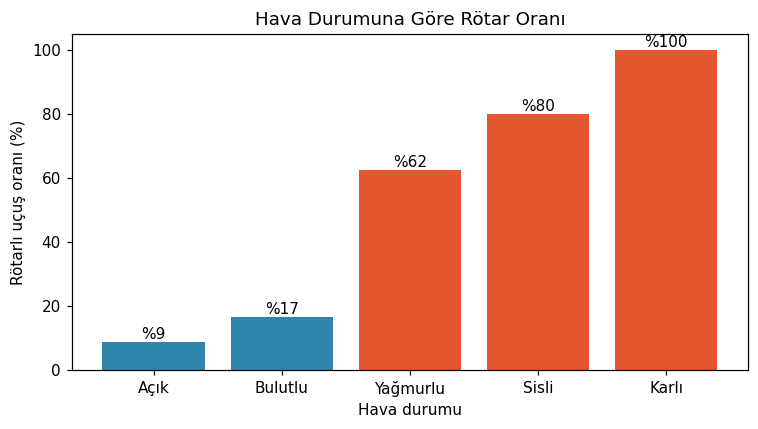

In [9]:
oran = temiz.groupby("hava_durumu")["rotar"].mean().sort_values() * 100
renkler = ["#2E86AB" if v < 50 else "#E4572E" for v in oran.values]

plt.figure(figsize=(7, 4))
cubuklar = plt.bar(oran.index, oran.values, color=renkler)
plt.bar_label(cubuklar, fmt="%%%.0f")
plt.title("Hava Durumuna Göre Rötar Oranı")
plt.xlabel("Hava durumu")
plt.ylabel("Rötarlı uçuş oranı (%)")
plt.ylim(0, 105)
plt.tight_layout()
plt.savefig("grafikler/1_hava_durumu_rotar.png", dpi=150)
plt.show()

### Grafik 2 — Görüş mesafesi ve önceki uçuş gecikmesi (dağılım grafiği)

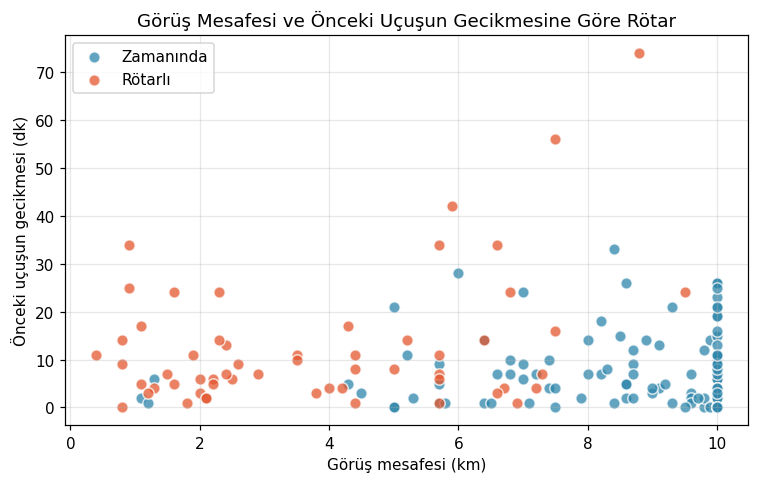

In [10]:
plt.figure(figsize=(7, 4.5))
for deger, renk, etiket in [(0, "#2E86AB", "Zamanında"), (1, "#E4572E", "Rötarlı")]:
    alt = temiz[temiz["rotar"] == deger]
    plt.scatter(alt["gorus_mesafesi"], alt["onceki_ucus_rotari"],
                c=renk, label=etiket, alpha=0.75, edgecolors="white", s=55)
plt.title("Görüş Mesafesi ve Önceki Uçuşun Gecikmesine Göre Rötar")
plt.xlabel("Görüş mesafesi (km)")
plt.ylabel("Önceki uçuşun gecikmesi (dk)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("grafikler/2_gorus_onceki_rotar.png", dpi=150)
plt.show()

### Grafik 3 — Günün saat dilimine göre rötar oranı

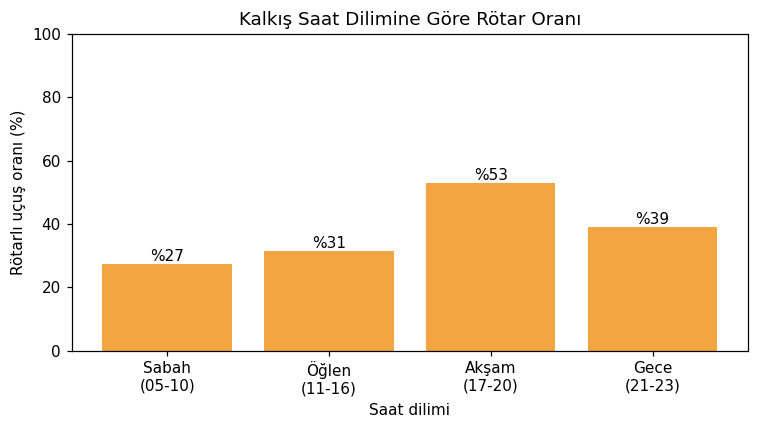

In [11]:
dilim = pd.cut(temiz["kalkis_saati"], bins=[4, 10, 16, 20, 23],
               labels=["Sabah\n(05-10)", "Öğlen\n(11-16)", "Akşam\n(17-20)", "Gece\n(21-23)"])
saat_oran = temiz.groupby(dilim, observed=True)["rotar"].mean() * 100

plt.figure(figsize=(7, 4))
c = plt.bar(saat_oran.index.astype(str), saat_oran.values, color="#F2A541")
plt.bar_label(c, fmt="%%%.0f")
plt.title("Kalkış Saat Dilimine Göre Rötar Oranı")
plt.xlabel("Saat dilimi")
plt.ylabel("Rötarlı uçuş oranı (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.savefig("grafikler/3_saat_dilimi_rotar.png", dpi=150)
plt.show()

### Keşif Bulguları
1. **Hava durumu en güçlü ayrıştırıcı:** Karlı havada uçuşların %100'ü, sisli havada %80'i, yağmurlu havada %62'si rötarlı; açık havada bu oran yalnızca %9.
2. **Görüş mesafesi belirleyici:** Rötarlı uçuşlarda ortalama görüş 3,8 km, zamanında uçuşlarda 8,4 km. Grafik 2'de kırmızı (rötarlı) noktalar düşük görüş tarafında toplanıyor.
3. **Zincirleme gecikme etkisi:** Önceki uçuşu gecikmiş uçaklar daha sık rötar yapıyor (rötarlılarda ortalama 12,8 dk, zamanındakilerde 8,2 dk).
4. **Akşam saatleri riskli:** 17:00–20:00 kalkışlarında rötar oranı %53, sabah (05–10) %27. Rötarlı uçuşlarda havalimanı yoğunluğu da daha yüksek (26,5'e karşı 21,9 kalkış/saat).
5. **Yanıltıcı ilişki uyarısı:** Rötarlı uçuşların ortalama mesafesi daha kısa görünüyor (878'e karşı 1.177 km). Ancak veri üretiminde mesafenin rötara hiçbir etkisi yok; bu fark tesadüf. Korelasyon nedensellik değildir.

## Aşama 4 — Model Kurma ve Eğitme
Kategorik sütunlar (hava durumu, gün) modelin anlayacağı sayılara çevrilir. Hava durumu, uçuş açısından
**olumsuzluk sırasına** göre kodlanır (Açık=0 … Karlı=4).

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

hava_kod = {"Açık": 0, "Bulutlu": 1, "Yağmurlu": 2, "Sisli": 3, "Karlı": 4}
gun_kod = {"Pzt": 0, "Sal": 1, "Çar": 2, "Per": 3, "Cum": 4, "Cmt": 5, "Paz": 6}

model_veri = temiz.copy()
model_veri["hava_kodu"] = model_veri["hava_durumu"].map(hava_kod)
model_veri["gun_kodu"] = model_veri["gun"].map(gun_kod)

OZELLIKLER = ["kalkis_saati", "gun_kodu", "hava_kodu", "ruzgar_hizi", "gorus_mesafesi",
              "havalimani_yogunlugu", "onceki_ucus_rotari", "mesafe_km"]
X = model_veri[OZELLIKLER]   # özellikler
y = model_veri["rotar"]      # hedef

# %75 eğitim, %25 test — stratify ile iki kümede de rötar oranı korunur
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)

X_train: (119, 8) | X_test: (40, 8)
y_train: (119,) | y_test: (40,)


### Ağaç derinliğinin seçimi (aşırı öğrenme kontrolü)
Derinlik arttıkça ağaç eğitim verisini ezberler. En iyi derinliği **test verisine bakmadan**, yalnızca eğitim
verisi üzerinde **5 katlı çapraz doğrulama** (`cross_val_score`) ile seçiyoruz; test kümesi en sona saklanır.

 max_depth  eğitim_%  CV_ortalama_%  CV_std_%
         1      84.9           81.7       6.0
         2      84.9           80.8       5.3
         3      89.1           81.6       5.4
         4      89.9           81.7       5.2
         5      89.9           81.0       4.9
         6      89.9           81.0       4.9
         7      89.9           81.0       4.9
         8      89.9           81.0       4.9


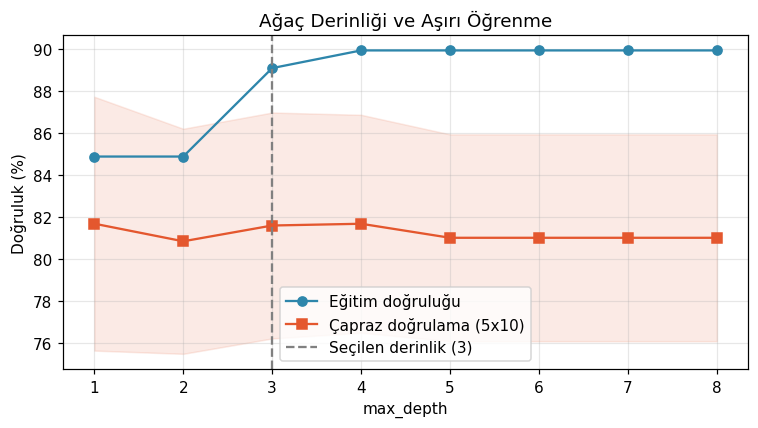

In [13]:
from sklearn.model_selection import cross_val_score, RepeatedStratifiedKFold

# 5 katlı çapraz doğrulama, farklı karıştırmalarla 10 kez tekrarlanır (küçük veride daha kararlı sonuç)
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
derinlikler = range(1, 9)
egitim_skor, cv_skor, cv_std = [], [], []
for d in derinlikler:
    m = DecisionTreeClassifier(max_depth=d, min_samples_leaf=5, random_state=42)
    s = cross_val_score(m, X_train, y_train, cv=cv)
    cv_skor.append(s.mean() * 100)
    cv_std.append(s.std() * 100)
    egitim_skor.append(m.fit(X_train, y_train).score(X_train, y_train) * 100)

print(pd.DataFrame({"max_depth": list(derinlikler), "eğitim_%": egitim_skor,
                    "CV_ortalama_%": cv_skor, "CV_std_%": cv_std}).round(1).to_string(index=False))

# CV skorları tüm derinliklerde ±%5 bandında; derin ağaç daha iyi genellemiyor, yalnızca ezberliyor.
# En iyi CV skoruna eşit olan ve birden fazla faktörü birlikte değerlendirebilen en sığ ağaç: derinlik 3
EN_IYI_DERINLIK = 3

plt.figure(figsize=(7, 4))
plt.plot(derinlikler, egitim_skor, "o-", label="Eğitim doğruluğu", color="#2E86AB")
plt.plot(derinlikler, cv_skor, "s-", label="Çapraz doğrulama (5x10)", color="#E4572E")
plt.fill_between(derinlikler, np.array(cv_skor) - np.array(cv_std), np.array(cv_skor) + np.array(cv_std),
                 color="#E4572E", alpha=0.12)
plt.axvline(EN_IYI_DERINLIK, ls="--", color="gray", label=f"Seçilen derinlik ({EN_IYI_DERINLIK})")
plt.title("Ağaç Derinliği ve Aşırı Öğrenme")
plt.xlabel("max_depth")
plt.ylabel("Doğruluk (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("grafikler/4_derinlik_asiri_ogrenme.png", dpi=150)
plt.show()

In [14]:
# Karar ağacı, çapraz doğrulamayla seçilen derinlikte eğitilir
model = DecisionTreeClassifier(max_depth=EN_IYI_DERINLIK, min_samples_leaf=5, random_state=42)
model.fit(X_train, y_train)
print("Model eğitildi ✔  | Ağaç derinliği:", model.get_depth(), "| Yaprak sayısı:", model.get_n_leaves())

Model eğitildi ✔  | Ağaç derinliği: 3 | Yaprak sayısı: 8


**Model seçim gerekçesi:** Hedef değişken iki sınıflı olduğu için bir sınıflandırma modeli gerekir.
`DecisionTreeClassifier`, "görüş 3 km'den azsa ve önceki uçuş 20 dk'dan fazla geciktiyse → rötar" gibi
**insanın okuyabildiği kurallar** öğrenir; bu da operasyon ekibine kararın nedenini açıklamayı kolaylaştırır.
Ayrıca sayısal ölçeklendirme gerektirmez ve doğrusal olmayan ilişkileri (ör. sis + yoğunluk birleşimi) yakalayabilir.
Küçük veri setinde ezberlemeyi önlemek için ağaç **derinlik 3** ve **yaprak başına en az 5 örnek**
(`min_samples_leaf=5`) ile sınırlandırılmıştır; bu seçim yukarıdaki çapraz doğrulama eğrisine dayanır.

## Aşama 5 — Tahmin ve Değerlendirme

In [15]:
from sklearn.metrics import accuracy_score, confusion_matrix

y_pred = model.predict(X_test)
egitim_dogruluk = model.score(X_train, y_train)
test_dogruluk = accuracy_score(y_test, y_pred)

print(f"Eğitim doğruluğu: %{egitim_dogruluk*100:.1f}")
print(f"Test doğruluğu  : %{test_dogruluk*100:.1f}")
print(f"Basit tahmin (hep 'zamanında' de) doğruluğu: %{(1 - y_test.mean())*100:.1f}")

cm = pd.DataFrame(confusion_matrix(y_test, y_pred),
                  index=["Gerçek: Zamanında", "Gerçek: Rötarlı"],
                  columns=["Tahmin: Zamanında", "Tahmin: Rötarlı"])
cm

Eğitim doğruluğu: %89.1
Test doğruluğu  : %82.5
Basit tahmin (hep 'zamanında' de) doğruluğu: %65.0


,Tahmin: Zamanında,Tahmin: Rötarlı
Gerçek: Zamanında,23,3
Gerçek: Rötarlı,4,10


### Hangi özellik daha belirleyici? (özellik önemi)

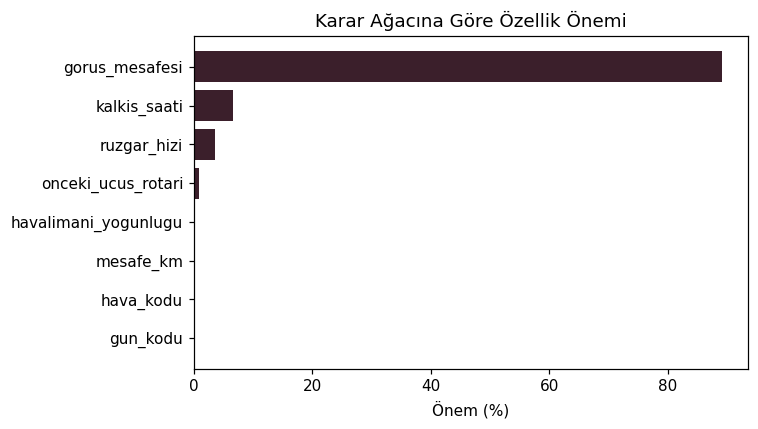

gorus_mesafesi          89.1
kalkis_saati             6.6
ruzgar_hizi              3.5
onceki_ucus_rotari       0.8
havalimani_yogunlugu     0.0
mesafe_km                0.0
hava_kodu                0.0
gun_kodu                 0.0
dtype: float64

In [16]:
onem = pd.Series(model.feature_importances_, index=OZELLIKLER).sort_values()
plt.figure(figsize=(7, 4))
plt.barh(onem.index, onem.values * 100, color="#3B1F2B")
plt.title("Karar Ağacına Göre Özellik Önemi")
plt.xlabel("Önem (%)")
plt.tight_layout()
plt.savefig("grafikler/5_ozellik_onemi.png", dpi=150)
plt.show()
(onem.sort_values(ascending=False) * 100).round(1)

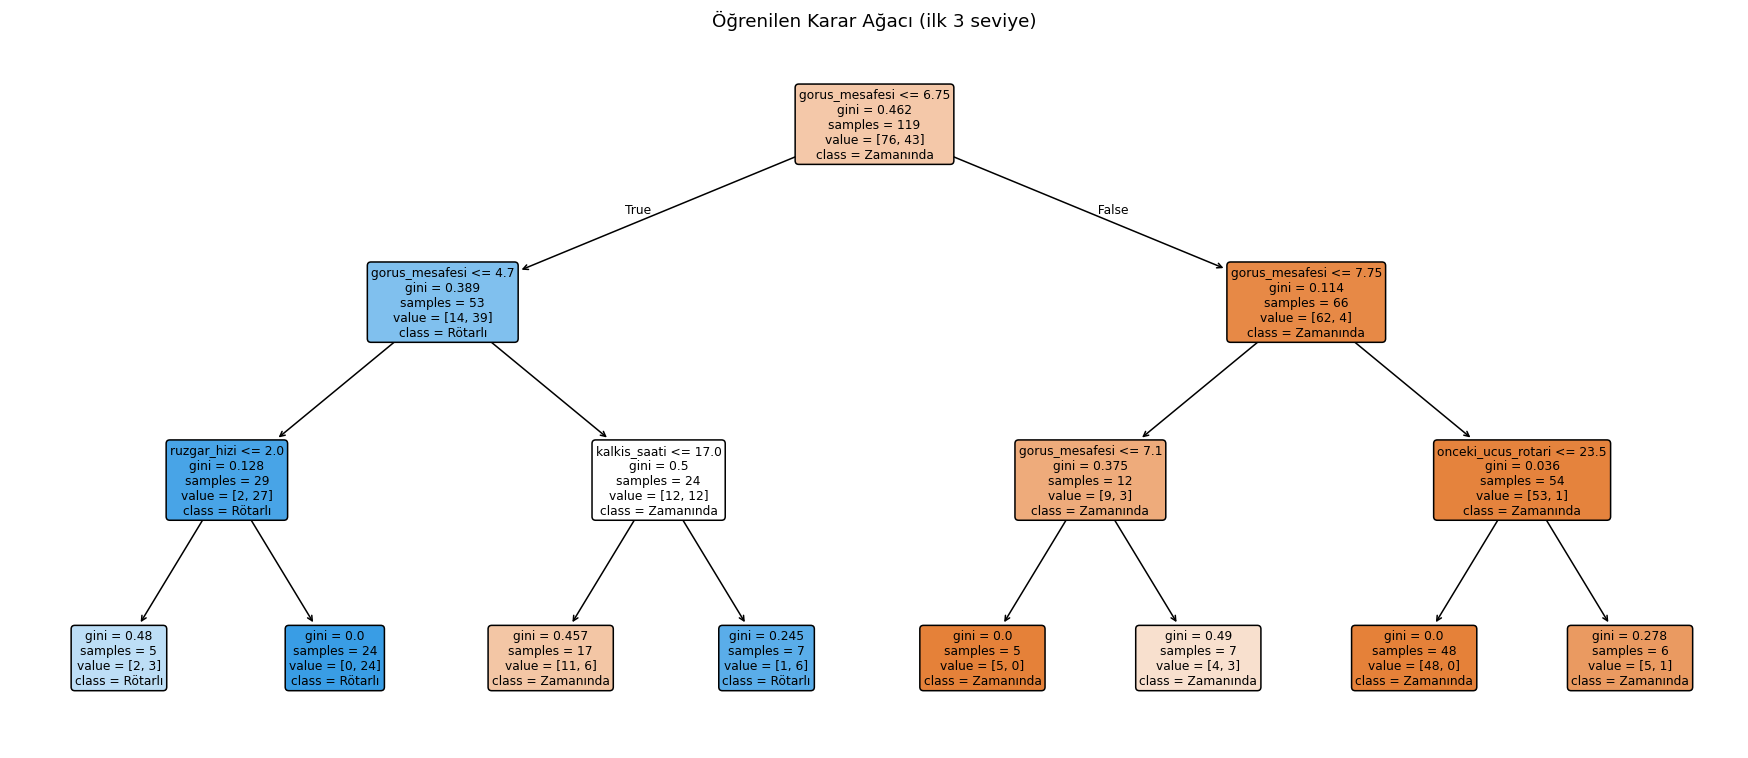

In [17]:
from sklearn.tree import plot_tree
plt.figure(figsize=(16, 7))
plot_tree(model, feature_names=OZELLIKLER, class_names=["Zamanında", "Rötarlı"],
          filled=True, rounded=True, fontsize=8, max_depth=3)
plt.title("Öğrenilen Karar Ağacı (ilk 3 seviye)")
plt.tight_layout()
plt.savefig("grafikler/6_karar_agaci.png", dpi=150)
plt.show()

### En az 3 yeni örnek için tahmin tablosu (girdi → tahmin)

In [18]:
yeni_ucuslar = pd.DataFrame([
    # sakin bir sabah uçuşu
    {"kalkis_saati": 7,  "gun": "Sal", "hava_durumu": "Açık",     "ruzgar_hizi": 6,  "gorus_mesafesi": 10,
     "havalimani_yogunlugu": 18, "onceki_ucus_rotari": 0,  "mesafe_km": 560},
    # yağmurlu, yoğun bir cuma akşamı
    {"kalkis_saati": 18, "gun": "Cum", "hava_durumu": "Yağmurlu", "ruzgar_hizi": 22, "gorus_mesafesi": 4.5,
     "havalimani_yogunlugu": 40, "onceki_ucus_rotari": 12, "mesafe_km": 1050},
    # sisli sabah, önceki uçuş da gecikmiş
    {"kalkis_saati": 6,  "gun": "Per", "hava_durumu": "Sisli",    "ruzgar_hizi": 5,  "gorus_mesafesi": 0.8,
     "havalimani_yogunlugu": 22, "onceki_ucus_rotari": 25, "mesafe_km": 690},
    # bulutlu öğlen, normal yoğunluk
    {"kalkis_saati": 13, "gun": "Çar", "hava_durumu": "Bulutlu",  "ruzgar_hizi": 11, "gorus_mesafesi": 8,
     "havalimani_yogunlugu": 24, "onceki_ucus_rotari": 5,  "mesafe_km": 1350},
])
girdi = yeni_ucuslar.assign(hava_kodu=yeni_ucuslar["hava_durumu"].map(hava_kod),
                            gun_kodu=yeni_ucuslar["gun"].map(gun_kod))[OZELLIKLER]
yeni_ucuslar["rotar_olasiligi_%"] = (model.predict_proba(girdi)[:, 1] * 100).round(0)
yeni_ucuslar["tahmin"] = np.where(model.predict(girdi) == 1, "Rötarlı", "Zamanında")
yeni_ucuslar[["kalkis_saati", "gun", "hava_durumu", "ruzgar_hizi", "gorus_mesafesi",
              "havalimani_yogunlugu", "onceki_ucus_rotari", "rotar_olasiligi_%", "tahmin"]]

,kalkis_saati,gun,hava_durumu,ruzgar_hizi,gorus_mesafesi,havalimani_yogunlugu,onceki_ucus_rotari,rotar_olasiligi_%,tahmin
0,7,Sal,Açık,6,10.0,18,0,0.0,Zamanında
1,18,Cum,Yağmurlu,22,4.5,40,12,100.0,Rötarlı
2,6,Per,Sisli,5,0.8,22,25,100.0,Rötarlı
3,13,Çar,Bulutlu,11,8.0,24,5,0.0,Zamanında


### Değerlendirme Notu — Model güvenilir mi?
- **Başarı:** Test doğruluğu **%82,5**. Her uçuşa "zamanında" diyen basit tahmin %65'te kalıyor; model bundan 17,5 puan daha iyi.
- **Aşırı öğrenme:** Eğitim (%89,1) ile test (%82,5) arasındaki 6,6 puanlık fark makul düzeyde. Derin ağaçlar eğitimde %90'a çıksa da çapraz doğrulama skorunu artırmadı. Bu yüzden sığ ağaç tercih edildi.
- **Hata analizi:** 14 rötarlı uçuşun 10'u yakalandı (duyarlılık %71), 4'ü kaçırıldı. 3 zamanında uçuş yanlışlıkla "rötarlı" etiketlendi. Yolcu için kaçırılan rötar daha maliyetli olduğundan ilk geliştirilecek nokta bu.
- **Sınırlılıklar:** Test kümesi 40 uçuş, yani her hata doğruluğu 2,5 puan değiştiriyor (CV std ±%5). Gerçek performans büyük olasılıkla %77–87 aralığında. Model kararının %89'unu görüş mesafesine dayandırıyor. Rüzgâr ve hava durumu, görüşle güçlü ilişkili olduğu için ayrı önem kazanamadı. Yapraklar saf olduğundan olasılıklar %0/%100 gibi aşırı kesin çıkıyor, yani kalibre değil. Son olarak veri bir simülasyon olduğu için bu başarı gerçek havalimanı verisinde garanti değil.
- **İyileştirme önerileri:** Gerçek veriyle (ör. ABD BTS On-Time Performance, METAR hava raporları) 1000+ uçuşla yeniden eğitmek. Random Forest ile kararlılığı artırmak. `class_weight="balanced"` ile rötarlı sınıfın duyarlılığını yükseltmek. Olasılık kalibrasyonu eklemek.

## Aşama 6 — Akıllı Tahmin Aracı (Mini Uygulama)
`tahmin_et()` fonksiyonu modelin sayısal çıktısını **okunur bir cümleye** çevirir.
`ucus_asistani()` ise kullanıcıdan `input()` ile bilgi alıp anında tahmin üretir.

In [19]:
def tahmin_et(kalkis_saati, gun, hava_durumu, ruzgar_hizi, gorus_mesafesi,
              havalimani_yogunlugu, onceki_ucus_rotari, mesafe_km):
    """Uçuş bilgilerini alır, rötar tahminini anlamlı bir cümle olarak döndürür."""
    satir = pd.DataFrame([{
        "kalkis_saati": kalkis_saati, "gun_kodu": gun_kod[gun], "hava_kodu": hava_kod[hava_durumu],
        "ruzgar_hizi": ruzgar_hizi, "gorus_mesafesi": gorus_mesafesi,
        "havalimani_yogunlugu": havalimani_yogunlugu, "onceki_ucus_rotari": onceki_ucus_rotari,
        "mesafe_km": mesafe_km}])[OZELLIKLER]
    olasilik = model.predict_proba(satir)[0, 1] * 100

    if olasilik >= 70:
        seviye, oneri = "YÜKSEK", "Aktarmanız varsa havayolunuzla iletişime geçin ve alternatif planlayın."
    elif olasilik >= 40:
        seviye, oneri = "ORTA", "Havalimanına çıkmadan önce uçuş durumunu tekrar kontrol edin."
    else:
        seviye, oneri = "DÜŞÜK", "Uçuşunuzun zamanında kalkması bekleniyor. İyi yolculuklar!"

    return (f"✈️  {gun} günü saat {kalkis_saati:02d}:00 kalkışlı, {hava_durumu.lower()} havadaki uçuşunuz için "
            f"rötar riski %{olasilik:.0f} → {seviye}. {oneri}")


# Örnek çalıştırmalar
print(tahmin_et(7, "Sal", "Açık", 6, 10, 18, 0, 560))
print(tahmin_et(18, "Cum", "Yağmurlu", 22, 4.5, 40, 12, 1050))
print(tahmin_et(6, "Per", "Sisli", 5, 0.8, 22, 25, 690))

✈️  Sal günü saat 07:00 kalkışlı, açık havadaki uçuşunuz için rötar riski %0 → DÜŞÜK. Uçuşunuzun zamanında kalkması bekleniyor. İyi yolculuklar!
✈️  Cum günü saat 18:00 kalkışlı, yağmurlu havadaki uçuşunuz için rötar riski %100 → YÜKSEK. Aktarmanız varsa havayolunuzla iletişime geçin ve alternatif planlayın.
✈️  Per günü saat 06:00 kalkışlı, sisli havadaki uçuşunuz için rötar riski %100 → YÜKSEK. Aktarmanız varsa havayolunuzla iletişime geçin ve alternatif planlayın.


In [20]:
def ucus_asistani():
    """Kullanıcıdan input() ile bilgi alan etkileşimli mini uygulama."""
    print("=== SkyTrack Rötar Asistanı ===")
    try:
        saat = int(input("Kalkış saati (5-23): "))
        gun = input("Gün (Pzt/Sal/Çar/Per/Cum/Cmt/Paz): ").strip()
        hava = input("Hava durumu (Açık/Bulutlu/Yağmurlu/Sisli/Karlı): ").strip()
        ruzgar = float(input("Rüzgâr hızı (knot): "))
        gorus = float(input("Görüş mesafesi (km): "))
        yogunluk = int(input("Havalimanı yoğunluğu (saatlik kalkış): "))
        onceki = int(input("Önceki uçuşun gecikmesi (dk): "))
        mesafe = int(input("Uçuş mesafesi (km): "))
    except Exception:
        # Not defteri otomatik çalıştırılırken (input yokken) örnek değerlerle gösterim
        print("(Etkileşimli girdi alınamadı — örnek değerlerle gösteriliyor)")
        saat, gun, hava, ruzgar, gorus, yogunluk, onceki, mesafe = 19, "Paz", "Karlı", 25, 2.0, 38, 15, 830
        print(f"Kalkış saati: {saat} | Gün: {gun} | Hava: {hava} | Rüzgâr: {ruzgar} kt | Görüş: {gorus} km | "
              f"Yoğunluk: {yogunluk} | Önceki rötar: {onceki} dk | Mesafe: {mesafe} km")
    print()
    print(tahmin_et(saat, gun, hava, ruzgar, gorus, yogunluk, onceki, mesafe))

ucus_asistani()

=== SkyTrack Rötar Asistanı ===
(Etkileşimli girdi alınamadı — örnek değerlerle gösteriliyor)
Kalkış saati: 19 | Gün: Paz | Hava: Karlı | Rüzgâr: 25 kt | Görüş: 2.0 km | Yoğunluk: 38 | Önceki rötar: 15 dk | Mesafe: 830 km

✈️  Paz günü saat 19:00 kalkışlı, karlı havadaki uçuşunuz için rötar riski %100 → YÜKSEK. Aktarmanız varsa havayolunuzla iletişime geçin ve alternatif planlayın.


## Aşama 7 — Dokümantasyon ve Özet
| | |
|---|---|
| **Problem** | Uçuş bilgilerinden 15 dk üzeri rötarı tahmin etmek (sınıflandırma) |
| **Veri** | 161 satırlık simülasyon veri seti → temizlik sonrası 159 satır, 8 özellik |
| **Yöntem** | Pandas ile temizleme + EDA, Matplotlib ile 6 grafik, scikit-learn `DecisionTreeClassifier(max_depth=3)` + çapraz doğrulama |
| **Sonuç** | Test doğruluğu **%82,5** (temel tahmin %65); rötarlı uçuşların %71'i yakalandı |
| **Çıkarım** | Kötü görüş (sis, kar, yağmur) ve akşam yoğunluğu rötarın en güçlü habercileri. Model basit ve açıklanabilir bir erken uyarı aracı olabilir; gerçek kullanım için gerçek veriyle yeniden eğitilmeli. |

**Teslim dosyaları:** Colab not defteri (bu dosya) · `ucus_rotar_verisi.csv` · Proje envanteri ve raporu (PDF) · Sunum (PPTX, 5 slayt)